In [1]:
from pathlib import Path
Path('figures').mkdir(exist_ok=True)
import numpy as np
import matplotlib.pyplot as plt

# Plot style matched to DeterMotif.ipynb
# Uses Matplotlib mathtext instead of external LaTeX, so it works without a TeX install.
PLOT_FIGSIZE = (2.5, 2)
LABEL_FS = 12
TICK_FS = 8
LEGEND_FS = 10
SMALL_LEGEND_FS = 8

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "font.serif": ["Computer Modern", "DejaVu Serif"],
    "mathtext.fontset": "cm",
})

import matplotlib.cm as cm
from matplotlib.colors import TwoSlopeNorm
import warnings
import math
import time
import matplotlib.ticker as ticker
from collections import defaultdict
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import matplotlib.ticker as ticker
import pickle
from scipy.linalg import solve_continuous_lyapunov
from scipy.signal import correlate
from scipy.integrate import simpson
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D
from sympy import integrate
warnings.filterwarnings('ignore')

In [2]:
def generate_graph_matrix(graph_type, size, params):
    import networkx as nx
    if graph_type == 'directed_chain':
        length = params.get('length', 1)
        G = nx.path_graph(length, create_using=nx.DiGraph())

    elif graph_type == 'loop':
        length = params.get('length', 1)
        G = nx.path_graph(length, create_using=nx.DiGraph())
        G.add_edge(length - 1, 0)

    else:
        raise ValueError("Invalid graph type")
    
    G = G.to_directed()
    return G, nx.to_numpy_array(G)

def generate_H(topology, diag_matrix):
    N = np.shape(topology)[0]
    D = np.zeros((N, N))
    for i in range(N):
        D[i][i] = sum(topology[i])
    return topology - D - diag_matrix

def generate_input(input_type, params, dim):

    def make_array(value, default=0):
        return np.array(value) if isinstance(value, list) else np.full(dim, value)

    if input_type == 'constant':
        c = make_array(params.get('c', 0))  
        def I(t):
            return c

    elif input_type == 'square':
        s = make_array(params.get('s', 0))
        start_time = params.get('start_time', 0)
        end_time = params.get('end_time', 1)
        def I(t):
            return s if start_time <= t <= end_time else np.zeros_like(s)

    elif input_type == 'noise':
        miu = make_array(params.get('miu', 0), default=None)
        sigma = make_array(params.get('sigma', 0), default=None)
        def I(t):
            noise = np.array([np.random.normal(m, s) if m is not None else 0 for m, s in zip(miu, sigma)])
            return noise
    
    # This is delta like function, but when using solve_ivp, this input might have problems as solve_ivp does not follow time order seriesly
    elif input_type == 'pulse':
        p = make_array(params.get('p', 0))
        p_time = params.get('p_time', 0)
        def I(t):
            return p if np.isclose(t, p_time, atol=1e-2) else np.zeros_like(p)
        
    elif input_type == 'zero':
        def I(t):
            return np.zeros(dim)

    else:
        raise ValueError("Invalid input type. Choose 'constant', 'pulse', 'noise', 'zero', or 'square'.")

    return I

class ODEEuler:
    def __init__(self, H, I, initial_v):
        self.H = H
        self.I = I
        self.initial_v = initial_v

    def H_function(self, t, v):
        return np.dot(self.H, v) + self.I(t)

    def I_function(self, t):
        return np.array([1, 0, ...])  

    def solve(self, t_span, t_eval=None):
        values = np.zeros((len(t_eval), len(self.initial_v)))
        values[0] = self.initial_v
        dt = (t_span[1] - t_span[0]) / len(t_eval)
        for i in range(1, len(t_eval)):
            t = t_eval[i-1]
            v = values[i-1]
            values[i] = v + dt * self.H_function(t, v)

        return t_eval, values

def generate_simulation(input_type, params, dim):
    def single_exp(x,a):
        return np.exp(-x/a)

    def sigmoid(x,a):
        return 2.0/(1.0+np.exp(x/a))
    
    def make_array(value, default=0):
        return np.array(value) if isinstance(value, list) else np.full(dim, value)
    
    if input_type == 'constant':
        def judge_stable(y_plot):
            stable = np.abs(y_plot[-2] - y_plot[-1]) / y_plot[-1]
            if stable < 1e-3:
                return 1
            else:
                print(stable)
                return 0
            
        t = make_array(params.get('t', 0))  
        y = make_array(params.get('y', 0))
        eta = params.get('eta', 0)

        threshold_time, decay_time, sigmoid_time, peak_list, amp_list = [[] for i in range(5)]
     
        for i in np.arange(np.shape(y)[1]):
            y_plot = y[:, i]
            peak_list.append(np.max(y_plot) - y_plot[0])
            if judge_stable(y_plot):
                fit_curve = y_plot[-1] - y_plot 
                amp_list.append(simpson(fit_curve, t))
                fit_curve = (fit_curve -  np.min(fit_curve)) / (np.max(fit_curve) - np.min(fit_curve))
                t_plot = t[:len(fit_curve)]
                r_single, _ = curve_fit(single_exp, t_plot, fit_curve)
                #plt.plot(t_plot, fit_curve, color = 'gray', alpha = 0.5)
                decay_time.append(r_single[0])  
                r_sigmoid, _ = curve_fit(sigmoid, t_plot, fit_curve)
                sigmoid_time.append(r_sigmoid[0])  

                delta_y = y[:, i] - y[0, i]
                y_val = np.max(delta_y) * eta
                time_scale_up = [t[j] for j in range(0, len(delta_y) - 1) if (delta_y[j] <= y_val and delta_y[j + 1] >= y_val)][0]
                threshold_time.append(time_scale_up)   
            else:
                print('time is not long enough')
        #plt.title('exp fitting curve')
        #plt.show()

        if 0: #show threshold
            for i in range(3):
                plt.plot(t, y[:, i] - y[0, i])
                plt.vlines(threshold_time[i], 0, np.max(y[:, i] - y[0, i]), linestyle = 'dotted')
            plt.xlim([0, 6])
            plt.show()

        return decay_time, threshold_time, sigmoid_time, peak_list, amp_list
    
    elif input_type == 'pulse' or input_type == 'zero':
        def judge_stable(y_plot):
            stable = np.abs(y_plot[-1]) / np.max(y_plot)
            if stable < 1e-3:
                return 1
            else:
                print(stable)
                return 0
        
        def truncate_list(a):
            return a[:next((i for i, value in enumerate(a) if value < a[0] * 0.01), len(a))]

        t = make_array(params.get('t', 0))  
        y = make_array(params.get('y', 0))

        peak = np.max(y, axis=0)
        peak_time = [t[i] for i in np.argmax(y, axis=0)]
        decay_time, amp = [[] for i in range(2)]
        
        for i in np.arange(np.shape(y)[1]):
            y_plot = y[:, i]
            if judge_stable(y_plot):
                area = simpson(y_plot, t)
                amp.append(area)
                
                fit_curve = y_plot[np.argmax(y_plot):]
                fit_curve = (fit_curve -  np.min(fit_curve)) / (np.max(fit_curve) - np.min(fit_curve))
                fit_curve = truncate_list(fit_curve)
                t_plot = t[:len(fit_curve)]
                
                r_single, _ = curve_fit(single_exp, t_plot, fit_curve)
                #plt.plot(t_plot, fit_curve, color = 'gray', alpha = 0.5)
                decay_time.append(r_single[0])         
            else:
                print('time is not long enough')
        #plt.title('fitting decay curve')
        #plt.show()

        for i in np.arange(np.shape(y)[1]):
            y_plot = y[:, i]
            fit_curve = y_plot
            fit_curve = (fit_curve -  np.min(fit_curve)) / (np.max(fit_curve) - np.min(fit_curve))
            t_plot = t[:len(fit_curve)]
            plt.plot(t_plot[:10000], fit_curve[:10000], color = 'gray', alpha = 0.5)
        plt.title('initial curve')
        plt.show()

        return peak, peak_time, decay_time, amp
    
    elif input_type == 'square':
        def judge_stable(y_plot):
            stable = np.abs(y_plot[-2] - y_plot[-1]) / np.max(y_plot)
            if stable < 1e-3:
                return 1
            else:
                print(stable)
                return 0
            
        t = make_array(params.get('t', 0))  
        y = make_array(params.get('y', 0))
        eta = params.get('eta', 0)

        peak, amp = [[] for i in range(2)]
     
        for i in np.arange(np.shape(y)[1]):
            y_plot = y[:, i]
            if judge_stable(y_plot):
                peak.append(np.max(y_plot))
                plt.plot(y_plot)
                area = simpson(y_plot, t) #simps(y_plot, t) #trapz(y_plot, np.array([0 for i in range(len(y_plot))]))
                amp.append(area)
            else:
                print('time is not long enough')
        plt.title('evolution')
        plt.show()

        return peak, amp

# Generate theoretical approximation
def generate_theory(input_type, params, dim):
    
    import networkx as nx
    def make_array(value, default=0):
        return np.array(value) if isinstance(value, list) else value
    
    if input_type == 'constant':
            
        H = make_array(params.get('H', 0))  
        strength = make_array(params.get('strength', 0))
        m = make_array(params.get('m', 0))  
        matrix = make_array(params.get('matrix', 0))
        eta = make_array(params.get('eta', 0))

        threshold, decay, decay_high, path = [[] for i in range(4)]
        peak, amp, sigmoid = [[] for i in range(3)]
        
        H_inv = np.linalg.inv(H)
        H_inv_two = np.linalg.inv(np.linalg.matrix_power(H, 2))
        H_inv_three = np.linalg.inv(np.linalg.matrix_power(H, 3))

        for area_idx in range(dim):
            peak.append(- H_inv[area_idx][m])
            amp.append(H_inv_two[area_idx][m])
            decay.append(- H_inv_two[area_idx][m] / H_inv[area_idx][m])
            decay_high.append(- H_inv_three[area_idx][m] / H_inv_two[area_idx][m])
            threshold.append(np.log(1.0 - eta) * H_inv_two[area_idx][m] / H_inv[area_idx][m])
            sigmoid.append(np.log((1.0 - eta) / (1.0 + eta)) * (H_inv_two[area_idx][m] / H_inv[area_idx][m]) / (2*np.log(2)))

            G = nx.from_numpy_array(matrix, create_using=nx.DiGraph)
            d = nx.dijkstra_path_length(G, m, area_idx, weight=1)
            path.append(d)
        # return relative_time, tau, tau_high_order, path, sigmoid_relative_time, peak_response, response_amplification
        return threshold, decay, decay_high, path, sigmoid, peak, amp

    elif input_type == 'pulse' or input_type == 'zero':
            
        H = make_array(params.get('H', 0))  
        strength = make_array(params.get('strength', 0))
        m = make_array(params.get('m', 0))  
        matrix = make_array(params.get('matrix', 0))

        initial_v = [0 if i != m else strength for i in range(dim)]
        
        try:
            eigen_val, eigen_matrix = np.linalg.eig(H)
            eigen_matrix_inv = np.linalg.inv(eigen_matrix)
            
        except:
            eigen_matrix_inv = np.zeros((np.shape(H)[0], np.shape(H)[0]))
        
        eig_max = np.max(np.real(eigen_val)) 
        tau = -1.0 / eig_max
        
        H_inv = np.linalg.inv(H)
        H_inv_two = np.linalg.inv(np.linalg.matrix_power(H, 2))
        H_inv_three = np.linalg.inv(np.linalg.matrix_power(H, 3))
            
        ti_amend, Hi_amend_long, Hi_amend_short, ti_direct, Hi_direct, path = [[] for i in range(6)]

        amp_list, decay_matrix = [[] for i in range(2)]

        for area_idx in range(dim):
         
            G = nx.from_numpy_array(matrix, create_using=nx.DiGraph)
            d = nx.dijkstra_path_length(G, m, area_idx, weight=1)
            path.append(d)
                       
            ti_direct.append(- H_inv_two[area_idx][m] / H_inv[area_idx][m])
            Hi_direct.append(strength * np.power(H_inv[area_idx][m] ,2) / np.power((2 * H_inv_three[area_idx][m] * H_inv[area_idx][m] - np.power(H_inv_two[area_idx][m],2)) ,0.5) )
            amp_list.append(- H_inv[area_idx][m])
            ti_amend.append(ti_direct[area_idx] + 1 / np.max(eigen_val))
            Hi_amend_long.append(Hi_direct[area_idx] / np.power(2 * math.pi , 0.5))
            Hi_amend_short.append(Hi_direct[area_idx] * np.power(d+1, 0.5) * np.power(d,d) / (np.exp(d) * np.math.factorial(int(d))) )

            x_p = Hi_amend_short[area_idx]
            HI = -np.dot(H_inv, np.array(initial_v))
            decay_matrix.append( (1 - 1/np.exp(1)) * HI[area_idx] / x_p )
        
        return ti_direct, Hi_direct, ti_amend, Hi_amend_long, Hi_amend_short, decay_matrix, amp_list, path

    elif input_type == 'square':
            
        H = make_array(params.get('H', 0))  
        strength = make_array(params.get('strength', 0))
        m = make_array(params.get('m', 0))  
        matrix = make_array(params.get('matrix', 0))
        eta = make_array(params.get('eta', 0))
        ts = make_array(params.get('ts', 0))

        peak_theory, amp_theory, path = [[] for i in range(3)]
        
        H_inv = np.linalg.inv(H)
        H_inv_two = np.linalg.inv(np.linalg.matrix_power(H, 2))

        for area_idx in range(dim):
            tau = - H_inv_two[area_idx][m] / H_inv[area_idx][m]
            peak_theory.append(-H_inv[area_idx][m] * (1.0 - np.exp( -ts / tau )))
            amp_theory.append( -H_inv[area_idx][m] * ts )
            G = nx.from_numpy_array(matrix, create_using=nx.DiGraph)
            d = nx.dijkstra_path_length(G, m, area_idx, weight=1)
            path.append(d)

        return peak_theory, amp_theory, path


def plot_eigs(H, title="Eigenvalues of H"):
    H = np.asarray(H)
    eigvals = np.linalg.eigvals(H)   # works for any square matrix

    plt.figure(figsize=PLOT_FIGSIZE)
    plt.scatter(eigvals.real, eigvals.imag, s=40)
    plt.axhline(0, linewidth=1)
    plt.axvline(0, linewidth=1)
    plt.xlabel("Real part", fontsize=LABEL_FS)
    plt.ylabel("Imaginary part", fontsize=LABEL_FS)
    plt.title(title, fontsize=LABEL_FS)
    plt.gca().set_aspect("equal", adjustable="datalim")  # makes circles look like circles
    plt.tight_layout()
    plt.show()

def chain_constant(N, weight, t_span, t_evel, net_name):

    G, matrix = generate_graph_matrix(net_name, N, {'length': N})
    matrix = matrix.T
    matrix = weight * matrix
    diag_matrix = np.zeros((N, N))
    beta = 1.0
    for i in range(N):
        diag_matrix[i][i] = beta
    H = generate_H(matrix, diag_matrix)
    plot_eigs(H)
    m = 0
    strength = 1
    eta = 1.0 - 1.0 / np.exp(1) #1.0/np.exp(1) 
    initial_v = [0 for i in range(N)]
    input_type = 'constant'
    params = {'c': [0 if i != 0 else strength for i in range(N)]}  
    I = generate_input(input_type, params, N)
    solver_euler = ODEEuler(H, I, initial_v)
    t_eval, solution_euler = solver_euler.solve(t_span, t_evel)

    simu_params = {'t': list(t_eval), 'y': list(solution_euler), 'eta': eta}
    decay_time, threshold_time, sigmoid_time, peak_list, amp_list  = generate_simulation(input_type, simu_params, N)
    
    theory_params = {'H': list(H), 'strength': strength, 'm': m, 'matrix': list(matrix.T), 'eta': eta}
    threshold, decay, decay_high, path, sigmoid, peak, amp = generate_theory(input_type, theory_params, N)
    print('peak:', np.array(peak_list) - np.array(peak))
    print('amp:', np.array(amp_list)-np.array(amp))
    print('time constant:', np.array(decay_time)-np.array(decay))
    np.save('figures/constant_peak_response_new_'+net_name+'.npy', peak_list)
    np.save('figures/constant_amplification_new_'+net_name+'.npy', amp_list)
    np.save('figures/constant_time_constant_new_'+net_name+'.npy', decay_time)

    np.save('figures/constant_peak_response_thr_'+net_name+'.npy', peak)
    np.save('figures/constant_amplification_thr_'+net_name+'.npy', amp)
    np.save('figures/constant_time_constant_thr_'+net_name+'.npy', decay)

def chain_pulse(N, weight, t_span, t_evel, net_name):

    G, matrix = generate_graph_matrix(net_name, N, {'length': N})
    matrix = matrix.T
    matrix = weight * matrix
    diag_matrix = np.zeros((N, N))
    beta = 1.0
    for i in range(N):
        diag_matrix[i][i] = beta
    H = generate_H(matrix, diag_matrix)
    plot_eigs(H)
    
    m = 0
    strength = 1
    
    initial_v = [0 if i != m else strength for i in range(N)]
    input_type = 'zero'
    params = {}
    I = generate_input(input_type, params, N)
    solver_euler = ODEEuler(H, I, initial_v)
    t_eval, solution_euler = solver_euler.solve(t_span, t_evel)
    simu_params = {'t': list(t_eval), 'y': list(solution_euler)}
    peak, peak_time, decay_time, amp = generate_simulation(input_type, simu_params, N)
    
    theory_params = {'H': list(H), 'strength': strength, 'm': m , 'matrix': list(matrix.T)}
    ti_direct, Hi_direct, ti_amend, Hi_amend_long, Hi_amend_short, decay_matrix, amp_thr, path = generate_theory(input_type, theory_params, N)

    np.save('figures/pulse_peak_response_new_'+net_name+'.npy', peak)
    np.save('figures/pulse_amplification_new_'+net_name+'.npy', amp)
    np.save('figures/pulse_time_constant_new_'+net_name+'.npy', peak_time)

    np.save('figures/pulse_peak_response_thr_'+net_name+'.npy', Hi_amend_short)
    np.save('figures/pulse_amplification_thr_'+net_name+'.npy', amp_thr)
    np.save('figures/pulse_time_constant_thr_'+net_name+'.npy', ti_amend)

# Sqaure for long ts
def chain_square(N, weight, t_span, t_evel, net_name, start_time, end_time):
    G, matrix = generate_graph_matrix(net_name, N, {'length': N})
    matrix = matrix.T
    matrix = weight * matrix
    
    diag_matrix = np.zeros((N, N))
    beta = 1.0
    for i in range(N):
        diag_matrix[i][i] = beta
    H = generate_H(matrix, diag_matrix)
    plot_eigs(H)
    m = 0
    strength = 1
    eta = 1.0 - 1.0 / np.exp(1) 

    initial_v = [0 for i in range(N)]
    input_type = 'square'
    params = {'s': [0 if i != 0 else strength for i in range(N)], 'start_time': start_time, 'end_time': end_time}

    ts = (end_time - start_time) 
    I = generate_input(input_type, params, N)
    solver_euler = ODEEuler(H, I, initial_v)
    t_eval, solution_euler = solver_euler.solve(t_span, t_evel)
    
    simu_params = {'t': list(t_eval), 'y': list(solution_euler), 'eta': eta, 'ts': ts}
    peak, amp  = generate_simulation(input_type, simu_params, N)
    np.save('figures/square_peak_response_new_'+net_name+'.npy', peak)
    np.save('figures/square_amplification_new_'+net_name+'.npy', amp)

    theory_params = {'H': list(H), 'strength': strength, 'm': m , 'matrix': list(matrix.T), 'eta': eta, 'ts': ts}
    peak_theory, amp_theory, path = generate_theory(input_type, theory_params, N)
    np.save('figures/square_peak_response_thr_'+net_name+'.npy', peak_theory)
    np.save('figures/square_amplification_thr_'+net_name+'.npy', amp_theory)

In [3]:
def H_feedforward_fan(
    n: int,
    w_0k: float = 1.0,   # 0 -> intermediate
    w_k2: float = 1.0,   # intermediate -> 2
    w_02: float = 1.0,   # direct 0 -> 2
    decay: float = 0.5,  # diagonal leak
):
    """
    Feedforward fan of n triangles:
        0 -> k -> 2 and 0 -> 2, for k = n intermediates

    Node indexing:
        0 : source
        1,3,5,... : intermediates
        2 : sink
    """
    if n < 1:
        raise ValueError("n must be >= 1")

    source = 0
    sink = 1
    intermediates = [(i) for i in range(2, n+2)]

    N = n + 2 
    W = np.zeros((N, N))

    # direct shortcut
    W[sink, source] = w_02

    # feedforward triangles
    for k in intermediates:
        W[k, source] = w_0k   # 0 -> k
        W[sink, k] = w_k2     # k -> 2

    # linear dynamics matrix
    sink_decay = np.zeros((N, N))
    sink_decay[sink][sink] = 1.0
    H = W - sink_decay
    source_decay = np.zeros((N, N)) 
    source_decay[source][source] = 1.0
    H = H - source_decay
    intemediate_decay = np.zeros((N, N))
    for k in intermediates:
        intemediate_decay[k][k] = 1 / decay
    H = H - intemediate_decay   
    return H, W

def H_chain(N, decay):
    W = np.zeros((N, N))
    for i in range(N-1):
        W[i+1][i] = 1.0
    
    source = 0
    sink = 1
    sink_decay = np.zeros((N, N))
    sink_decay[sink][sink] = 1.0
    H = W - sink_decay
    source_decay = np.zeros((N, N)) 
    source_decay[source][source] = 1.0
    H = H - source_decay
    if N > 2:
        intemediate_decay = np.zeros((N, N))
        for k in range(2, N):
            intemediate_decay[k][k] = 1  / decay
        H = H - intemediate_decay   
    return H, W

def H_parallel_chains(length, number, decay):
    """
    Build a directed network with `number` parallel feedforward chains
    from source=0 to sink=1.

    Parameters
    ----------
    length : int
        Chain length in edges (0 -> ... -> 1). Must be >= 1.
        length=1 means direct edges 0->1 (one per chain; they sum).
    number : int
        Number of parallel chains of the given length. Must be >= 1.
    decay : float
        Intermediate-node decay factor. Intermediate nodes get diagonal
        decay = 1/decay (matching your original convention). Must be > 0.

    Returns
    -------
    H : (N,N) ndarray
        System matrix H = W - diag(decays).
    W : (N,N) ndarray
        Weighted adjacency with edges i->j stored as W[j,i].
    """
    if length < 1:
        raise ValueError("length must be >= 1 (number of edges from source to sink).")
    if number < 1:
        raise ValueError("number must be >= 1.")
    if decay <= 0:
        raise ValueError("decay must be > 0.")

    source, sink = 0, 1

    # Each chain contributes (length-1) intermediate nodes.
    n_inter_per_chain = max(0, length - 1)
    N = 2 + number * n_inter_per_chain

    W = np.zeros((N, N), dtype=float)

    # Build each chain: 0 -> v1 -> v2 -> ... -> 1
    for c in range(number):
        start = 2 + c * n_inter_per_chain
        inter_nodes = list(range(start, start + n_inter_per_chain))

        path = [source] + inter_nodes + [sink]
        for u, v in zip(path[:-1], path[1:]):
            W[v, u] += 1.0  # allow multiple chains to sum weights on same edge (only happens when length=1)

    # Diagonal "decay" terms: source and sink = 1, intermediates = 1/decay
    diag = np.zeros(N, dtype=float)
    diag[source] = 1.0
    diag[sink] = 1.0
    if n_inter_per_chain > 0:
        diag[2:] = 1.0 / decay

    H = W - np.diag(diag)
    return H, W

def change_tau(): 

    decay_list = np.linspace(0.1, 10.0, num=10)
    peak_simu = []
    peak_thr = []
    peak_thr_2 = []
    time_simu = []
    time_thr = []
    chain_simu_1 = []
    chain_simu_2 = []
    for decay_id in decay_list:
        H, W = H_feedforward_fan(n=1, decay=decay_id)
        t_span = [0, 100]
        t_evel = np.linspace(0, 100, 100000)

        m = 0
        strength = 1
        eta = 1.0 - 1.0 / np.exp(1) 
        N = np.shape(H)[0]
        initial_v = [0 for i in range(N)]
        input_type = 'constant'
        params = {'c': [0 if i != 0 else strength for i in range(N)]}  
        I = generate_input(input_type, params, N)
        solver_euler = ODEEuler(H, I, initial_v)
        t_eval, solution_euler = solver_euler.solve(t_span, t_evel)

        simu_params = {'t': list(t_eval), 'y': list(solution_euler), 'eta': eta}
        decay_time, threshold_time, sigmoid_time, peak_list, amp_list  = generate_simulation(input_type, simu_params, N)
        peak_simu.append(peak_list[1])
        peak_thr.append( 1 + decay_id )
        peak_thr_2.append( decay_id )
        time_simu.append(decay_time[1])
        tau_2 = decay_id
        time_thr.append( 2.0 +  tau_2 ** 2 / (1+tau_2))

        chain_n = 2
        H_chain_1, _ = H_chain(N=chain_n, decay=decay_id)
        initial_v = [0 for i in range(chain_n)]
        params = {'c': [0 if i != 0 else strength for i in range(chain_n)]}  
        I = generate_input(input_type, params, chain_n)
        solver_chain_1 = ODEEuler(H_chain_1, I, initial_v)
        t_eval_1, solution_euler_1 = solver_chain_1.solve(t_span, t_evel)
        simu_params_1 = {'t': list(t_eval_1), 'y': list(solution_euler_1), 'eta': eta}
        decay_time_1, threshold_time_1, sigmoid_time_1, peak_list_1, amp_list_1  = generate_simulation(input_type, simu_params_1, chain_n)
        chain_simu_1.append(decay_time_1[1])

        chain_n_2 = 3
        H_chain_2, _ = H_chain(N=chain_n_2, decay=decay_id)
        initial_v = [0 for i in range(chain_n_2)]
        params = {'c': [0 if i != 0 else strength for i in range(chain_n_2)]}  
        I = generate_input(input_type, params, chain_n_2)
        solver_chain_2 = ODEEuler(H_chain_2, I, initial_v)
        t_eval_2, solution_euler_2 = solver_chain_2.solve(t_span, t_evel)
        simu_params_2 = {'t': list(t_eval_2), 'y': list(solution_euler_2), 'eta': eta}
        decay_time_2, threshold_time_2, sigmoid_time_2, peak_list_2, amp_list_2  = generate_simulation(input_type, simu_params_2, chain_n_2)
        chain_simu_2.append(decay_time_2[2])

    fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
    ax.scatter(np.array(decay_list), peak_simu, s=100, marker='o', color='blue', edgecolors='none', zorder=3, label=r'$Sim.$')
    ax.plot(np.array(decay_list), peak_thr, linestyle='--', linewidth=2.2, color='blue', zorder=2, label=r'$Thr.$')
    ax.plot(np.array(decay_list), peak_thr_2, linestyle='--', linewidth=2.2, color='gray', zorder=2, label=r'$R_2$')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    #ax.set_xticks(np.arange(1, 10))
    ax.tick_params(axis='both', which='major', labelsize=TICK_FS)
    plt.legend(frameon=False, fontsize=LEGEND_FS)
    plt.xlabel(r'$\gamma_j$', fontsize=LABEL_FS)
    plt.ylabel(r'$Peak\ response$', fontsize=LABEL_FS)
    plt.tight_layout()
    plt.savefig(f'figures/short_vs_long_peak.pdf', dpi=300)
    plt.show()

    fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
    ax.scatter(np.array(decay_list), time_simu, s=100, marker='o', color='blue', edgecolors='none', zorder=3, label=r'$Sim.$')
    ax.plot(np.array(decay_list), time_thr, linestyle='--', linewidth=2.2, color='blue', zorder=2, label=r'$Thr.$')
    ax.scatter(np.array(decay_list), chain_simu_1, s=100, marker='o', color='orange', edgecolors='none', zorder=3, label=r'$Sim. \ for \ chain \ 1$')
    ax.scatter(np.array(decay_list), chain_simu_2, s=100, marker='o', color='green', edgecolors='none', zorder=3, label=r'$Sim. \ for \ chain \ 2$')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    #ax.set_xticks(np.arange(1, 10))
    ax.tick_params(axis='both', which='major', labelsize=TICK_FS)
    plt.xlabel(r'$\gamma_j$', fontsize=LABEL_FS)
    plt.ylabel(r'$Time \ constant$', fontsize=LABEL_FS)
    plt.legend(frameon=False, fontsize=LEGEND_FS)
    plt.tight_layout()
    plt.savefig(f'figures/short_vs_long_time.pdf', dpi=300)
    plt.show()
    
#change_tau()

def chain_n():
    peak_simu = []
    peak_thr = []
    time_simu = []
    time_thr = []
    peak_thr_2 = []
    chain_simu_1 = []   
    chain_simu_2 = []
    f_num_list= np.arange(1, 16, 2)
    for f_num in f_num_list:
        
        H, W = H_feedforward_fan(n=f_num, decay=0.1)
        t_span = [0, 100]
        t_evel = np.linspace(0, 100, 100000)

        m = 0
        strength = 1
        eta = 1.0 - 1.0 / np.exp(1) 
        N = np.shape(H)[0]
        initial_v = [0 for i in range(N)]
        input_type = 'constant'
        params = {'c': [0 if i != 0 else strength for i in range(N)]}  
        I = generate_input(input_type, params, N)
        solver_euler = ODEEuler(H, I, initial_v)
        t_eval, solution_euler = solver_euler.solve(t_span, t_evel)

        simu_params = {'t': list(t_eval), 'y': list(solution_euler), 'eta': eta}
        decay_time, threshold_time, sigmoid_time, peak_list, amp_list  = generate_simulation(input_type, simu_params, N)
        
        chain_n = 2
        H_chain_1, _ = H_chain(N=chain_n, decay=2.0)
        initial_v = [0 for i in range(chain_n)]
        params = {'c': [0 if i != 0 else strength for i in range(chain_n)]}  
        I = generate_input(input_type, params, chain_n)
        solver_chain_1 = ODEEuler(H_chain_1, I, initial_v)
        t_eval_1, solution_euler_1 = solver_chain_1.solve(t_span, t_evel)
        simu_params_1 = {'t': list(t_eval_1), 'y': list(solution_euler_1), 'eta': eta}
        decay_time_1, threshold_time_1, sigmoid_time_1, peak_list_1, amp_list_1  = generate_simulation(input_type, simu_params_1, chain_n)
        chain_simu_1.append(decay_time_1[1])

        H_chain_2, _ = H_parallel_chains(length=2, number=f_num, decay=2.0)
        chain_n_2 = np.shape(H_chain_2)[0]
        initial_v = [0 for i in range(chain_n_2)]
        params = {'c': [0 if i != 0 else strength for i in range(chain_n_2)]}  
        I = generate_input(input_type, params, chain_n_2)
        solver_chain_2 = ODEEuler(H_chain_2, I, initial_v)
        t_eval_2, solution_euler_2 = solver_chain_2.solve(t_span, t_evel)
        simu_params_2 = {'t': list(t_eval_2), 'y': list(solution_euler_2), 'eta': eta}
        decay_time_2, threshold_time_2, sigmoid_time_2, peak_list_2, amp_list_2  = generate_simulation(input_type, simu_params_2, chain_n_2)
        chain_simu_2.append(decay_time_2[1])

        peak_simu.append(peak_list[1])
        tau_2 = 0.1
        peak_thr.append( 1 + tau_2 * f_num )
        peak_thr_2.append( tau_2 * f_num )
        time_simu.append(decay_time[1])
        time_thr.append( 2.0 + (f_num* tau_2 ** 2) / (1+f_num * tau_2))

    fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
    ax.scatter(np.array(f_num_list), peak_simu, s=100, marker='o', color='blue', edgecolors='none', zorder=3, label=r'$Sim.$')
    ax.plot(np.array(f_num_list), peak_thr, linestyle='--', linewidth=2.2, color='blue', zorder=2, label=r'$Thr.$')
    ax.plot(np.array(f_num_list), peak_thr_2, linestyle='--', linewidth=2.2, color='gray', zorder=2, label=r'$R_2$')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    #ax.set_xticks(np.arange(1, 10))
    ax.tick_params(axis='both', which='major', labelsize=TICK_FS)
    plt.legend(frameon=False, fontsize=LEGEND_FS)
    plt.xlabel(r'$n(\Delta)$', fontsize=LABEL_FS)
    plt.ylabel(r'$Peak \ response$', fontsize=LABEL_FS)
    plt.tight_layout()
    plt.savefig(f'figures/n_short_vs_long_peak.pdf', dpi=300)
    plt.show()

    fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
    ax.scatter(np.array(f_num_list), time_simu, s=100, marker='o', color='blue', edgecolors='none', zorder=3, label=r'$Sim.$')
    ax.plot(np.array(f_num_list), time_thr, linestyle='--', linewidth=2.2, color='blue', zorder=2, label=r'$Thr.$')
    ax.scatter(np.array(f_num_list), chain_simu_1, s=100, marker='o', color='orange', edgecolors='none', zorder=3, label=r'$Sim. \ for \ chain \ 1$')
    ax.scatter(np.array(f_num_list), chain_simu_2, s=100, marker='o', color='green', edgecolors='none', zorder=3, label=r'$Sim. \ for \ chain \ 2$')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    #ax.set_xticks(np.arange(1, 10))
    ax.tick_params(axis='both', which='major', labelsize=TICK_FS)
    plt.xlabel(r'$n(\Delta)$', fontsize=LABEL_FS)
    plt.ylabel(r'$Time \ constant$', fontsize=LABEL_FS)
    plt.legend(frameon=False, fontsize=LEGEND_FS)
    plt.tight_layout()
    plt.savefig(f'figures/n_short_vs_long_time.pdf', dpi=300)
    plt.show()

#chain_n()


def chain_weight():
    peak_simu = []
    peak_thr = []
    time_simu = []
    time_thr = []
    peak_thr_2 = []
    chain_simu_1 = []   
    chain_simu_2 = []
    #f_num_list= np.arange(1, 16, 2)
    weight_list = np.arange(1, 10, 1)
    for weight in weight_list:
        
        H, W = H_feedforward_fan(n=1, w_0k = weight, w_k2 =weight, decay=2.0)
        t_span = [0, 100]
        t_evel = np.linspace(0, 100, 100000)

        m = 0
        strength = 1
        eta = 1.0 - 1.0 / np.exp(1) 
        N = np.shape(H)[0]
        initial_v = [0 for i in range(N)]
        input_type = 'constant'
        params = {'c': [0 if i != 0 else strength for i in range(N)]}  
        I = generate_input(input_type, params, N)
        solver_euler = ODEEuler(H, I, initial_v)
        t_eval, solution_euler = solver_euler.solve(t_span, t_evel)

        simu_params = {'t': list(t_eval), 'y': list(solution_euler), 'eta': eta}
        decay_time, threshold_time, sigmoid_time, peak_list, amp_list  = generate_simulation(input_type, simu_params, N)
        
        chain_n = 2
        H_chain_1, _ = H_chain(N=chain_n, decay=2.0)
        initial_v = [0 for i in range(chain_n)]
        params = {'c': [0 if i != 0 else strength for i in range(chain_n)]}  
        I = generate_input(input_type, params, chain_n)
        solver_chain_1 = ODEEuler(H_chain_1, I, initial_v)
        t_eval_1, solution_euler_1 = solver_chain_1.solve(t_span, t_evel)
        simu_params_1 = {'t': list(t_eval_1), 'y': list(solution_euler_1), 'eta': eta}
        decay_time_1, threshold_time_1, sigmoid_time_1, peak_list_1, amp_list_1  = generate_simulation(input_type, simu_params_1, chain_n)
        chain_simu_1.append(decay_time_1[1])

        H_chain_2_initial, _ = H_parallel_chains(length=2, number=1, decay=2.0)
        H_chain_2 = np.asarray(H_chain_2_initial).copy()
        mask = ~np.eye(H_chain_2.shape[0], dtype=bool)   # True off-diagonal
        H_chain_2[mask] *= weight
        chain_n_2 = np.shape(H_chain_2)[0]
        initial_v = [0 for i in range(chain_n_2)]
        params = {'c': [0 if i != 0 else strength for i in range(chain_n_2)]}  
        I = generate_input(input_type, params, chain_n_2)
        solver_chain_2 = ODEEuler(H_chain_2, I, initial_v)
        t_eval_2, solution_euler_2 = solver_chain_2.solve(t_span, t_evel)
        simu_params_2 = {'t': list(t_eval_2), 'y': list(solution_euler_2), 'eta': eta}
        decay_time_2, threshold_time_2, sigmoid_time_2, peak_list_2, amp_list_2  = generate_simulation(input_type, simu_params_2, chain_n_2)
        chain_simu_2.append(decay_time_2[1])

        peak_simu.append(peak_list[1])
        tau_2 = 2.0
        A_ratio = weight ** 2 
        peak_thr.append( 1 + tau_2 * A_ratio )
        peak_thr_2.append( tau_2 * A_ratio )
        time_simu.append(decay_time[1])
        time_thr.append( 2.0 + (A_ratio* tau_2 ** 2) / (1+A_ratio * tau_2))
    colors = ['#286113', '#418726', '#8FC31F']
    fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
    ax.scatter(np.array(weight_list)**2, peak_simu, s=50, marker='o', color=colors[0], edgecolors='none', zorder=3, label=r'$sim.$')
    ax.plot(np.array(weight_list)**2, peak_thr, linestyle='--', linewidth=2.2, color=colors[0], zorder=2, label=r'$th.$')
    #ax.plot(np.array(weight_list)**2, peak_thr_2, linestyle='--', linewidth=2.2, color='gray', zorder=2, #label=r'$R_2$')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    #ax.set_xticks(np.arange(1, 10))
    ax.tick_params(axis='both', which='major', labelsize=TICK_FS)
    plt.legend(frameon=False, fontsize=LEGEND_FS)
    plt.xlabel(r'$A_r$', fontsize=LABEL_FS)
    plt.ylabel(r'$R_{FF}$', fontsize=LABEL_FS)
    plt.tight_layout()
    plt.savefig(f'figures/weight_short_vs_long_peak.pdf', dpi=300)
    plt.show()

    fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
    ax.scatter(np.array(weight_list)**2, time_simu, s=50, marker='o', color=colors[0], edgecolors='none', zorder=3, label=r'$sim.$')
    ax.plot(np.array(weight_list)**2, time_thr, linestyle='--', linewidth=2.2, color=colors[0], zorder=2, label=r'$th.$')
    ax.scatter(np.array(weight_list)**2, chain_simu_1, s=50, marker='o', color='orange', edgecolors='none', zorder=3, label=r'$short \ chain$')
    ax.scatter(np.array(weight_list)**2, chain_simu_2, s=50, marker='o', color=colors[2], edgecolors='none', zorder=3, label=r'$long \ chain$')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    #ax.set_xticks(np.arange(1, 10))
    ax.tick_params(axis='both', which='major', labelsize=TICK_FS)
    plt.xlabel(r'$A_r$', fontsize=LABEL_FS)
    plt.ylabel(r'$\tau_{FF}$', fontsize=LABEL_FS)
    plt.legend(frameon=False, fontsize=LEGEND_FS)
    plt.tight_layout()
    plt.savefig(f'figures/weight_short_vs_long_time.pdf', dpi=300)
    plt.show()

'''
theory_params = {'H': list(H), 'strength': strength, 'm': m, 'matrix': list(np.matrix.T), 'eta': eta}
threshold, decay, decay_high, path, sigmoid, peak, amp = generate_theory(input_type, theory_params, N)
print('peak:', np.array(peak_list) - np.array(peak))
print('amp:', np.array(amp_list)-np.array(amp))
print('time constant:', np.array(decay_time)-np.array(decay))
'''

"\ntheory_params = {'H': list(H), 'strength': strength, 'm': m, 'matrix': list(np.matrix.T), 'eta': eta}\nthreshold, decay, decay_high, path, sigmoid, peak, amp = generate_theory(input_type, theory_params, N)\nprint('peak:', np.array(peak_list) - np.array(peak))\nprint('amp:', np.array(amp_list)-np.array(amp))\nprint('time constant:', np.array(decay_time)-np.array(decay))\n"

In [4]:
def H_feedback_fan(
    n: int,
    w_2k: float = 1.0,   # 2 -> intermediate
    w_k0: float = 1.0,   # intermediate -> 0
    w_20: float = 1.0,   # direct 2 -> 0
    decay: float = 0.5,  # diagonal leak (intermediates use 1/decay in your code)
):
    """
    Feedback fan of n triangles:
        2 -> k -> 0 and 2 -> 0, for k = n intermediates

    Convention: W[post, pre] (column is presynaptic/source, row is postsynaptic/target)

    Node indexing:
        0 : sink (feedback target)
        1 : source (feedback origin)  <-- we will set source=1 as "2" node? No, see below.
    """
    if n < 1:
        raise ValueError("n must be >= 1")

    # Keep the same sizing / indexing pattern as your function, but make it explicit:
    # We'll use:
    #   node 0 = target (was "source" in your text)
    #   node 1 = origin (was "sink" in your code)
    target = 0          # corresponds to "0" in the diagram
    origin = 1          # corresponds to "2" in the diagram
    intermediates = [i for i in range(2, n + 2)]
    N = n + 2

    W = np.zeros((N, N))

    # direct edge: 2 -> 0   (origin -> target)
    W[origin, target] = w_20

    # feedback triangles: 2 -> k -> 0
    for k in intermediates:
        W[k, origin] = w_2k   # 2 -> k
        W[target, k] = w_k0   # k -> 0

    # linear dynamics matrix H = W - (diagonal leaks)
    H = W.copy()

    # leak on target and origin (you used 1.0)
    H[target, target] -= 1.0
    H[origin, origin] -= 1.0

    # leak on intermediates (you used 1/decay)
    for k in intermediates:
        H[k, k] -= (1.0 / decay)

    return H, W

def change_FB_tau(): 

    decay_list = np.linspace(0.1, 0.9, num=9)
    peak_simu = []
    peak_thr = []
    peak_thr_2 = []
    time_simu = []
    time_thr = []
    chain_simu_1 = []
    chain_simu_2 = []
    for decay_id in decay_list:
        H, W = H_feedback_fan(n=1, decay=decay_id)
        t_span = [0, 100]
        t_evel = np.linspace(0, 100, 100000)

        m = 0
        strength = 1
        eta = 1.0 - 1.0 / np.exp(1) 
        N = np.shape(H)[0]
        initial_v = [0 for i in range(N)]
        input_type = 'constant'
        params = {'c': [0 if i != 0 else strength for i in range(N)]}  
        I = generate_input(input_type, params, N)
        solver_euler = ODEEuler(H, I, initial_v)
        t_eval, solution_euler = solver_euler.solve(t_span, t_evel)

        simu_params = {'t': list(t_eval), 'y': list(solution_euler), 'eta': eta}
        decay_time, threshold_time, sigmoid_time, peak_list, amp_list  = generate_simulation(input_type, simu_params, N)
        peak_simu.append(peak_list[1])
        peak_thr.append( 1 / (1 - decay_id) )
        #peak_thr_2.append( decay_id )
        time_simu.append(decay_time[1])
        time_thr.append( -decay_id + (2 + decay_id) / (1 - decay_id) )

        chain_n = 2
        H_chain_1, _ = H_chain(N=chain_n, decay=decay_id)
        initial_v = [0 for i in range(chain_n)]
        params = {'c': [0 if i != 0 else strength for i in range(chain_n)]}  
        I = generate_input(input_type, params, chain_n)
        solver_chain_1 = ODEEuler(H_chain_1, I, initial_v)
        t_eval_1, solution_euler_1 = solver_chain_1.solve(t_span, t_evel)
        simu_params_1 = {'t': list(t_eval_1), 'y': list(solution_euler_1), 'eta': eta}
        decay_time_1, threshold_time_1, sigmoid_time_1, peak_list_1, amp_list_1  = generate_simulation(input_type, simu_params_1, chain_n)
        chain_simu_1.append(decay_time_1[1])

        chain_n_2 = 3
        H_chain_2, _ = H_chain(N=chain_n_2, decay=decay_id)
        initial_v = [0 for i in range(chain_n_2)]
        params = {'c': [0 if i != 0 else strength for i in range(chain_n_2)]}  
        I = generate_input(input_type, params, chain_n_2)
        solver_chain_2 = ODEEuler(H_chain_2, I, initial_v)
        t_eval_2, solution_euler_2 = solver_chain_2.solve(t_span, t_evel)
        simu_params_2 = {'t': list(t_eval_2), 'y': list(solution_euler_2), 'eta': eta}
        decay_time_2, threshold_time_2, sigmoid_time_2, peak_list_2, amp_list_2  = generate_simulation(input_type, simu_params_2, chain_n_2)
        chain_simu_2.append(decay_time_2[2])
    colors = ['#005895', '#0079C1', '#67B7D2']
    fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
    ax.scatter(np.array(decay_list), peak_simu, s=50, marker='o', color=colors[0], edgecolors='none', zorder=3, label=r'$sim.$')
    ax.plot(np.array(decay_list), peak_thr, linestyle='--', linewidth=2.2, color=colors[0], zorder=2, label=r'$th.$')
    #ax.plot(np.array(decay_list), peak_thr_2, linestyle='--', linewidth=2.2, color='gray', zorder=2, label=r'$R_2$')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    #ax.set_xticks(np.arange(1, 10))
    ax.tick_params(axis='both', which='major', labelsize=TICK_FS)
    plt.legend(frameon=False, fontsize=LEGEND_FS)
    plt.xlabel(r'$\gamma_j$', fontsize=LABEL_FS)
    plt.ylabel(r'$R_{FB}$', fontsize=LABEL_FS)
    plt.tight_layout()
    plt.savefig(f'figures/FB_short_vs_long_peak.pdf', dpi=300)
    plt.show()

    fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
    ax.scatter(np.array(decay_list), time_simu, s=50, marker='o', color=colors[0], edgecolors='none', zorder=3, label=r'$sim.$')
    ax.plot(np.array(decay_list), time_thr, linestyle='--', linewidth=2.2, color=colors[0], zorder=2, label=r'$th.$')
    ax.scatter(np.array(decay_list), chain_simu_1, s=50, marker='o', color='orange', edgecolors='none', zorder=3, label=r'$short \ chain$')
    ax.scatter(np.array(decay_list), chain_simu_2, s=50, marker='o', color=colors[2], edgecolors='none', zorder=3, label=r'$long \ chain$')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    #ax.set_xticks(np.arange(1, 10))
    ax.tick_params(axis='both', which='major', labelsize=TICK_FS)
    plt.xlabel(r'$\gamma_j$', fontsize=LABEL_FS)
    plt.ylabel(r'$\tau_{FB}$', fontsize=LABEL_FS)
    plt.legend(frameon=False, fontsize=LEGEND_FS)
    plt.tight_layout()
    plt.savefig(f'figures/FB_short_vs_long_time.pdf', dpi=300)
    plt.show()
    
#change_FB_tau()

def chain_FB_n():
    peak_simu = []
    peak_thr = []
    time_simu = []
    time_thr = []
    peak_thr_2 = []
    chain_simu_1 = []   
    chain_simu_2 = []
    f_num_list= np.arange(1, 10, 2)
    for f_num in f_num_list:
        
        H, W = H_feedback_fan(n=f_num, decay=0.1)
        t_span = [0, 100]
        t_evel = np.linspace(0, 100, 100000)

        m = 0
        strength = 1
        eta = 1.0 - 1.0 / np.exp(1) 
        N = np.shape(H)[0]
        initial_v = [0 for i in range(N)]
        input_type = 'constant'
        params = {'c': [0 if i != 0 else strength for i in range(N)]}  
        I = generate_input(input_type, params, N)
        solver_euler = ODEEuler(H, I, initial_v)
        t_eval, solution_euler = solver_euler.solve(t_span, t_evel)

        simu_params = {'t': list(t_eval), 'y': list(solution_euler), 'eta': eta}
        decay_time, threshold_time, sigmoid_time, peak_list, amp_list  = generate_simulation(input_type, simu_params, N)
        
        chain_n = 2
        H_chain_1, _ = H_chain(N=chain_n, decay=0.1)
        initial_v = [0 for i in range(chain_n)]
        params = {'c': [0 if i != 0 else strength for i in range(chain_n)]}  
        I = generate_input(input_type, params, chain_n)
        solver_chain_1 = ODEEuler(H_chain_1, I, initial_v)
        t_eval_1, solution_euler_1 = solver_chain_1.solve(t_span, t_evel)
        simu_params_1 = {'t': list(t_eval_1), 'y': list(solution_euler_1), 'eta': eta}
        decay_time_1, threshold_time_1, sigmoid_time_1, peak_list_1, amp_list_1  = generate_simulation(input_type, simu_params_1, chain_n)
        chain_simu_1.append(decay_time_1[1])
     
        H_chain_2, _ = H_parallel_chains(length=2, number=f_num, decay=0.1)
        chain_n_2 = np.shape(H_chain_2)[0]
        initial_v = [0 for i in range(chain_n_2)]
        params = {'c': [0 if i != 0 else strength for i in range(chain_n_2)]}  
        I = generate_input(input_type, params, chain_n_2)
        solver_chain_2 = ODEEuler(H_chain_2, I, initial_v)
        t_eval_2, solution_euler_2 = solver_chain_2.solve(t_span, t_evel)
        simu_params_2 = {'t': list(t_eval_2), 'y': list(solution_euler_2), 'eta': eta}
        decay_time_2, threshold_time_2, sigmoid_time_2, peak_list_2, amp_list_2  = generate_simulation(input_type, simu_params_2, chain_n_2)
        chain_simu_2.append(decay_time_2[1])
        d_time = 0.1
        peak_simu.append(peak_list[1])
        peak_thr.append( 1 / (1 - f_num * d_time) )
        #peak_thr_2.append( 2 * f_num )
        time_simu.append(decay_time[1])
        time_thr.append( -d_time + (2 + d_time) / (1 - f_num * d_time) )
    colors = ['#005895', '#0079C1', '#67B7D2']
    fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
    ax.scatter(np.array(f_num_list), peak_simu, s=100, marker='o', color=colors[0], edgecolors='none', zorder=3, label=r'$sim.$')
    ax.plot(np.array(f_num_list), peak_thr, linestyle='--', linewidth=2.2, color=colors[0], zorder=2, label=r'$th.$')
    #ax.plot(np.array(f_num_list), peak_thr_2, linestyle='--', linewidth=2.2, color='gray', zorder=2, label=r'$R_2$')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    #ax.set_xticks(np.arange(1, 10))
    ax.tick_params(axis='both', which='major', labelsize=TICK_FS)
    plt.legend(frameon=False, fontsize=LEGEND_FS)
    plt.xlabel(r'$n(\Delta)$', fontsize=LABEL_FS)
    plt.ylabel(r'$R_{FB}$', fontsize=LABEL_FS)
    plt.tight_layout()
    plt.savefig(f'figures/FB_n_short_vs_long_peak.pdf', dpi=300)
    plt.show()

    fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
    ax.scatter(np.array(f_num_list), time_simu, s=100, marker='o', color=colors[0], edgecolors='none', zorder=3, label=r'$sim.$')
    ax.plot(np.array(f_num_list), time_thr, linestyle='--', linewidth=2.2, color=colors[0], zorder=2, label=r'$th.$')
    ax.scatter(np.array(f_num_list), chain_simu_1, s=100, marker='o', color=colors[1], edgecolors='none', zorder=3, label=r'$sim. \ for \ chain \ 1$')
    ax.scatter(np.array(f_num_list), chain_simu_2, s=100, marker='o', color=colors[2], edgecolors='none', zorder=3, label=r'$sim. \ for \ chain \ 2$')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    #ax.set_xticks(np.arange(1, 10))
    ax.tick_params(axis='both', which='major', labelsize=TICK_FS)
    plt.xlabel(r'$n(\Delta)$', fontsize=LABEL_FS)
    plt.ylabel(r'$\tau_{FB}$', fontsize=LABEL_FS)
    plt.legend(frameon=False, fontsize=LEGEND_FS)
    plt.tight_layout()
    
    plt.savefig(f'figures/FB_n_short_vs_long_time.pdf', dpi=300)
    plt.show()

#chain_FB_n()


def chain_FB_weight():
    peak_simu = []
    peak_thr = []
    time_simu = []
    time_thr = []
    peak_thr_2 = []
    chain_simu_1 = []   
    chain_simu_2 = []
    #f_num_list= np.arange(1, 10, 2)
    weight_list = np.linspace(0.1, 3, 10)
    for weight in weight_list:
        
        H, W = H_feedback_fan(n=1, w_2k = weight, w_k0 = weight, decay=0.1)
        t_span = [0, 100]
        t_evel = np.linspace(0, 100, 100000)

        m = 0
        strength = 1
        eta = 1.0 - 1.0 / np.exp(1) 
        N = np.shape(H)[0]
        initial_v = [0 for i in range(N)]
        input_type = 'constant'
        params = {'c': [0 if i != 0 else strength for i in range(N)]}  
        I = generate_input(input_type, params, N)
        solver_euler = ODEEuler(H, I, initial_v)
        t_eval, solution_euler = solver_euler.solve(t_span, t_evel)

        simu_params = {'t': list(t_eval), 'y': list(solution_euler), 'eta': eta}
        decay_time, threshold_time, sigmoid_time, peak_list, amp_list  = generate_simulation(input_type, simu_params, N)
        
        chain_n = 2
        H_chain_1, _ = H_chain(N=chain_n, decay=2.0)
        initial_v = [0 for i in range(chain_n)]
        params = {'c': [0 if i != 0 else strength for i in range(chain_n)]}  
        I = generate_input(input_type, params, chain_n)
        solver_chain_1 = ODEEuler(H_chain_1, I, initial_v)
        t_eval_1, solution_euler_1 = solver_chain_1.solve(t_span, t_evel)
        simu_params_1 = {'t': list(t_eval_1), 'y': list(solution_euler_1), 'eta': eta}
        decay_time_1, threshold_time_1, sigmoid_time_1, peak_list_1, amp_list_1  = generate_simulation(input_type, simu_params_1, chain_n)
        chain_simu_1.append(decay_time_1[1])
     
        H_chain_2_initial, _ = H_parallel_chains(length=2, number=1, decay=2.0)
        H_chain_2 = np.asarray(H_chain_2_initial).copy()
        mask = ~np.eye(H_chain_2.shape[0], dtype=bool)   # True off-diagonal
        H_chain_2[mask] *= weight
        chain_n_2 = np.shape(H_chain_2)[0]
        initial_v = [0 for i in range(chain_n_2)]
        params = {'c': [0 if i != 0 else strength for i in range(chain_n_2)]}  
        I = generate_input(input_type, params, chain_n_2)
        solver_chain_2 = ODEEuler(H_chain_2, I, initial_v)
        t_eval_2, solution_euler_2 = solver_chain_2.solve(t_span, t_evel)
        simu_params_2 = {'t': list(t_eval_2), 'y': list(solution_euler_2), 'eta': eta}
        decay_time_2, threshold_time_2, sigmoid_time_2, peak_list_2, amp_list_2  = generate_simulation(input_type, simu_params_2, chain_n_2)
        chain_simu_2.append(decay_time_2[1])
        d_time = 0.1
        A_weight = weight ** 2
        peak_simu.append(peak_list[1])
        peak_thr.append( 1 / (1 - A_weight * d_time) )
        #peak_thr_2.append( 2 * f_num )
        time_simu.append(decay_time[1])
        time_thr.append( -d_time + (2 + d_time) / (1 - A_weight * d_time) )
    colors = ['#005895', '#0079C1', '#67B7D2']
    fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
    ax.scatter(np.array(weight_list)**2, peak_simu, s=50, marker='o', color=colors[0], edgecolors='none', zorder=3, label=r'$sim.$')
    ax.plot(np.array(weight_list)**2, peak_thr, linestyle='--', linewidth=2.2, color=colors[0], zorder=2, label=r'$th.$')
    #ax.plot(np.array(f_num_list), peak_thr_2, linestyle='--', linewidth=2.2, color='gray', zorder=2, label=r'$R_2$')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    #ax.set_xticks(np.arange(1, 10))
    ax.tick_params(axis='both', which='major', labelsize=TICK_FS)
    plt.legend(frameon=False, fontsize=LEGEND_FS)
    plt.xlabel(r'$A^{\times}$', fontsize=LABEL_FS)
    plt.ylabel(r'$R_{FB}$', fontsize=LABEL_FS)
    plt.tight_layout()
    plt.savefig(f'figures/weight_FB_short_vs_long_peak.pdf', dpi=300)
    plt.show()

    fig, ax = plt.subplots(figsize=PLOT_FIGSIZE)
    ax.scatter(np.array(weight_list)**2, time_simu, s=50, marker='o', color=colors[0], edgecolors='none', zorder=3, label=r'$sim.$')
    ax.plot(np.array(weight_list)**2, time_thr, linestyle='--', linewidth=2.2, color=colors[0], zorder=2, label=r'$th.$')
    ax.scatter(np.array(weight_list)**2, chain_simu_1, s=50, marker='o', color='orange', edgecolors='none', zorder=3, label=r'$short \ chain $')
    ax.scatter(np.array(weight_list)**2, chain_simu_2, s=50, marker='o', color=colors[2], edgecolors='none', zorder=3, label=r'$long \ chain $')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    #ax.set_xticks(np.arange(1, 10))
    ax.tick_params(axis='both', which='major', labelsize=TICK_FS)
    plt.xlabel(r'$A^{\times}$', fontsize=LABEL_FS)
    plt.ylabel(r'$\tau_{FB}$', fontsize=LABEL_FS)
    plt.legend(frameon=False, fontsize=LEGEND_FS)
    plt.tight_layout()
    
    plt.savefig(f'figures/weight_FB_short_vs_long_time.pdf', dpi=300)
    plt.show()



In [5]:
# Cached data + plot-only workflow
# First run computes and stores the simulation results in CACHE_JSON.
# Later style edits only need to rerun `records = load_or_build_plot_records()` and the plot functions.

import json
import os

CACHE_JSON = 'FF_vs_FB_cached_plot_records_tau2_2.json'


def _to_jsonable(obj):
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, (np.floating, np.integer)):
        return obj.item()
    if isinstance(obj, dict):
        return {key: _to_jsonable(value) for key, value in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_to_jsonable(value) for value in obj]
    return obj


def _simulate_constant_response(H, response_idx=1, t_span=(0, 100), n_eval=100000):
    t_eval_grid = np.linspace(t_span[0], t_span[1], n_eval)
    strength = 1
    eta = 1.0 - 1.0 / np.exp(1)
    N = np.shape(H)[0]
    initial_v = [0 for _ in range(N)]
    input_type = 'constant'
    params = {'c': [0 if i != 0 else strength for i in range(N)]}
    I = generate_input(input_type, params, N)
    solver_euler = ODEEuler(H, I, initial_v)
    t_eval, solution_euler = solver_euler.solve(list(t_span), t_eval_grid)
    simu_params = {'t': list(t_eval), 'y': list(solution_euler), 'eta': eta}
    decay_time, threshold_time, sigmoid_time, peak_list, amp_list = generate_simulation(input_type, simu_params, N)
    return peak_list[response_idx], decay_time[response_idx]


def build_plot_records(cache_path=CACHE_JSON):
    records = {}

    # FF: vary gamma_j
    decay_list = np.linspace(0.1, 10.0, num=10)
    peak_simu, peak_thr, peak_thr_2 = [], [], []
    time_simu, time_thr, chain_simu_1, chain_simu_2 = [], [], [], []
    for decay_id in decay_list:
        H, _ = H_feedforward_fan(n=1, decay=decay_id)
        peak_val, time_val = _simulate_constant_response(H, response_idx=1)
        peak_simu.append(peak_val)
        peak_thr.append(1 + decay_id)
        peak_thr_2.append(decay_id)
        time_simu.append(time_val)
        time_thr.append(2.0 + decay_id ** 2 / (1 + decay_id))

        H_chain_1, _ = H_chain(N=2, decay=decay_id)
        _, chain_time_1 = _simulate_constant_response(H_chain_1, response_idx=1)
        chain_simu_1.append(chain_time_1)

        H_chain_2, _ = H_chain(N=3, decay=decay_id)
        _, chain_time_2 = _simulate_constant_response(H_chain_2, response_idx=2)
        chain_simu_2.append(chain_time_2)

    records['ff_gamma'] = {
        'x': decay_list,
        'peak_simu': peak_simu,
        'peak_thr': peak_thr,
        'peak_thr_2': peak_thr_2,
        'time_simu': time_simu,
        'time_thr': time_thr,
        'chain_simu_1': chain_simu_1,
        'chain_simu_2': chain_simu_2,
    }

    # FF: vary number of triangles
    # Match the FF weight-ratio A_r panel: the intermediate-node time scale is tau_2 = 2.0.
    # With this parameterization, the theory
    #     tau_FF(n) = 2 + n*tau_2^2 / (1 + n*tau_2)
    # saturates to 2 + tau_2 = 4 as n(Delta) increases.
    tau_2 = 2.0
    f_num_list = np.arange(1, 16, 2)
    peak_simu, peak_thr, peak_thr_2 = [], [], []
    time_simu, time_thr, chain_simu_1, chain_simu_2 = [], [], [], []
    for f_num in f_num_list:
        H, _ = H_feedforward_fan(n=f_num, decay=tau_2)
        peak_val, time_val = _simulate_constant_response(H, response_idx=1)

        # Reference cases for the FF motif:
        # short chain: 0 -> 1
        # long chain:  0 -> intermediate -> 1 with the same tau_2.
        # These are limits/reference cases, so they should not depend on f_num.
        H_chain_1, _ = H_chain(N=2, decay=tau_2)
        _, chain_time_1 = _simulate_constant_response(H_chain_1, response_idx=1)
        chain_simu_1.append(chain_time_1)

        H_chain_2, _ = H_chain(N=3, decay=tau_2)
        _, chain_time_2 = _simulate_constant_response(H_chain_2, response_idx=2)
        chain_simu_2.append(chain_time_2)

        peak_simu.append(peak_val)
        peak_thr.append(1 + tau_2 * f_num)
        peak_thr_2.append(tau_2 * f_num)
        time_simu.append(time_val)
        time_thr.append(2.0 + (f_num * tau_2 ** 2) / (1 + f_num * tau_2))

    records['ff_triangles'] = {
        'tau_2': tau_2,
        'time_saturation': 2.0 + tau_2,
        'x': f_num_list,
        'peak_simu': peak_simu,
        'peak_thr': peak_thr,
        'peak_thr_2': peak_thr_2,
        'time_simu': time_simu,
        'time_thr': time_thr,
        'chain_simu_1': chain_simu_1,
        'chain_simu_2': chain_simu_2,
    }

    # FB: vary gamma_j
    decay_list = np.linspace(0.1, 0.9, num=9)
    peak_simu, peak_thr = [], []
    time_simu, time_thr, chain_simu_1, chain_simu_2 = [], [], [], []
    for decay_id in decay_list:
        H, _ = H_feedback_fan(n=1, decay=decay_id)
        peak_val, time_val = _simulate_constant_response(H, response_idx=1)
        peak_simu.append(peak_val)
        peak_thr.append(1 / (1 - decay_id))
        time_simu.append(time_val)
        time_thr.append(-decay_id + (2 + decay_id) / (1 - decay_id))

        H_chain_1, _ = H_chain(N=2, decay=decay_id)
        _, chain_time_1 = _simulate_constant_response(H_chain_1, response_idx=1)
        chain_simu_1.append(chain_time_1)

        H_chain_2, _ = H_chain(N=3, decay=decay_id)
        _, chain_time_2 = _simulate_constant_response(H_chain_2, response_idx=2)
        chain_simu_2.append(chain_time_2)

    records['fb_gamma'] = {
        'x': decay_list,
        'peak_simu': peak_simu,
        'peak_thr': peak_thr,
        'time_simu': time_simu,
        'time_thr': time_thr,
        'chain_simu_1': chain_simu_1,
        'chain_simu_2': chain_simu_2,
    }

    # FB: vary number of triangles
    f_num_list = np.arange(1, 10, 2)
    peak_simu, peak_thr = [], []
    time_simu, time_thr, chain_simu_1, chain_simu_2 = [], [], [], []
    for f_num in f_num_list:
        H, _ = H_feedback_fan(n=f_num, decay=0.1)
        peak_val, time_val = _simulate_constant_response(H, response_idx=1)

        H_chain_1, _ = H_chain(N=2, decay=0.1)
        _, chain_time_1 = _simulate_constant_response(H_chain_1, response_idx=1)
        chain_simu_1.append(chain_time_1)

        H_chain_2, _ = H_parallel_chains(length=2, number=f_num, decay=0.1)
        _, chain_time_2 = _simulate_constant_response(H_chain_2, response_idx=1)
        chain_simu_2.append(chain_time_2)

        d_time = 0.1
        peak_simu.append(peak_val)
        peak_thr.append(1 / (1 - f_num * d_time))
        time_simu.append(time_val)
        time_thr.append(-d_time + (2 + d_time) / (1 - f_num * d_time))

    records['fb_triangles'] = {
        'x': f_num_list,
        'peak_simu': peak_simu,
        'peak_thr': peak_thr,
        'time_simu': time_simu,
        'time_thr': time_thr,
        'chain_simu_1': chain_simu_1,
        'chain_simu_2': chain_simu_2,
    }

    with open(cache_path, 'w') as f:
        json.dump(_to_jsonable(records), f, indent=2)
    return _to_jsonable(records)


def load_or_build_plot_records(cache_path=CACHE_JSON, force=False):
    if (not force) and os.path.exists(cache_path):
        with open(cache_path, 'r') as f:
            return json.load(f)
    return build_plot_records(cache_path=cache_path)


def _finish_determotif_style(ax, xlabel, ylabel, legend_anchor=(-0.05, 1.1)):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.xlabel(xlabel, fontsize=LABEL_FS)
    plt.ylabel(ylabel, fontsize=LABEL_FS)
    plt.legend(fontsize=LEGEND_FS, frameon=False, loc='upper left', bbox_to_anchor=legend_anchor)
    ax.tick_params(axis='x', which='both', labelsize=TICK_FS)
    ax.tick_params(axis='y', which='both', labelsize=TICK_FS)
    plt.tight_layout()


def plot_cached_gamma(records, motif='ff'):
    key = f'{motif}_gamma'
    data = records[key]
    x = np.array(data['x'])
    color = '#286113' if motif == 'ff' else '#005895'
    motif_label = 'FF' if motif == 'ff' else 'FB'
    peak_path = 'figures/short_vs_long_peak.pdf' if motif == 'ff' else 'figures/FB_short_vs_long_peak.pdf'
    time_path = 'figures/short_vs_long_time.pdf' if motif == 'ff' else 'figures/FB_short_vs_long_time.pdf'

    plt.figure(figsize=PLOT_FIGSIZE)
    plt.scatter(x, data['peak_simu'], color=color, label=r'$sim.$')
    plt.plot(x, data['peak_thr'], linestyle='--', color=color, alpha=0.8, linewidth=2.0, label=r'$th.$')
    #if motif == 'ff':
    #    plt.plot(x, data['peak_thr_2'], linestyle='--', color='gray', alpha=0.8, linewidth=2.0, label=r'$R_2$')
    ax = plt.gca()
    _finish_determotif_style(ax, r'$\gamma_j$', fr'$R_{{{motif_label}}}$')
    plt.savefig(peak_path, dpi=300)
    plt.show()

    plt.figure(figsize=PLOT_FIGSIZE)
    plt.scatter(x, data['time_simu'], color=color, label=r'$sim.$')
    plt.plot(x, data['time_thr'], linestyle='--', color=color, alpha=0.8, linewidth=2.0, label=r'$th.$')
    if motif == 'ff':
        plt.scatter(x, data['chain_simu_1'], color='orange', marker='o', linestyle='-', label=r'$short \ chain$')
        plt.scatter(x, data['chain_simu_2'], color='#8FC31F', marker='o', linestyle='-', label=r'$long \ chain$')
    else:
        plt.scatter(x, data['chain_simu_1'], color='orange', marker='o', linestyle='-', label=r'$short \ chain$')
        plt.scatter(x, data['chain_simu_2'], color='#67B7D2', marker='o', linestyle='-', label=r'$long \ chain$')
    ax = plt.gca()
    _finish_determotif_style(ax, r'$\gamma_j$', fr'$\tau_{{{motif_label}}}$', legend_anchor=(-0.05, 1.2))
    plt.savefig(time_path, dpi=300)
    plt.show()


def plot_cached_triangles(records, motif='ff'):
    key = f'{motif}_triangles'
    data = records[key]
    x = np.array(data['x'])
    color = '#286113' if motif == 'ff' else '#005895'
    motif_label = 'FF' if motif == 'ff' else 'FB'
    peak_path = 'figures/n_short_vs_long_peak.pdf' if motif == 'ff' else 'figures/FB_n_short_vs_long_peak.pdf'
    time_path = 'figures/n_short_vs_long_time.pdf' if motif == 'ff' else 'figures/FB_n_short_vs_long_time.pdf'

    plt.figure(figsize=PLOT_FIGSIZE)
    plt.scatter(x, data['peak_simu'], color=color, label=r'$sim.$')
    plt.plot(x, data['peak_thr'], linestyle='--', color=color, alpha=0.8, linewidth=2.0, label=r'$th.$')
    #if motif == 'ff':
    #    plt.plot(x, data['peak_thr_2'], linestyle='--', color='gray', alpha=0.8, linewidth=2.0, label=r'$R_2$')
    ax = plt.gca()
    _finish_determotif_style(ax, r'$n(\Delta)$', fr'$R_{{{motif_label}}}$')
    plt.savefig(peak_path, dpi=300)
    plt.show()

    plt.figure(figsize=PLOT_FIGSIZE)
    plt.scatter(x, data['time_simu'], color=color, label=r'$sim.$')
    plt.plot(x, data['time_thr'], linestyle='--', color=color, alpha=0.8, linewidth=2.0, label=r'$th.$')
    if motif == 'ff':
        plt.scatter(x, data['chain_simu_1'], color='orange', marker='o', linestyle='-', label=r'$short \ chain$')
        plt.scatter(x, data['chain_simu_2'], color='#8FC31F', marker='o', linestyle='-', label=r'$long \ chain$')
    else:
        plt.scatter(x, data['chain_simu_1'], color='orange', marker='o', linestyle='-', label=r'$short \ chain$')
        plt.scatter(x, data['chain_simu_2'], color='#67B7D2', marker='o', linestyle='-', label=r'$long \ chain$')
    ax = plt.gca()
    _finish_determotif_style(ax, r'$n(\Delta)$', fr'$\tau_{{{motif_label}}}$', legend_anchor=(-0.05, 1.2))
    plt.savefig(time_path, dpi=300)
    plt.show()


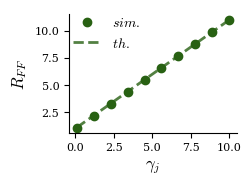

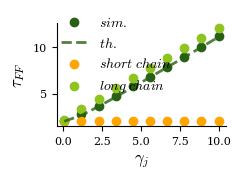

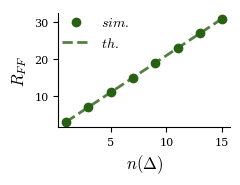

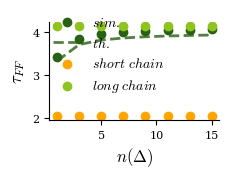

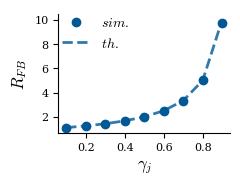

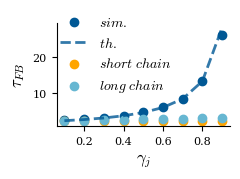

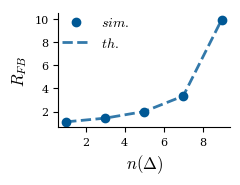

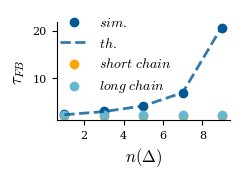

In [6]:
# Plot from cached records.
# This version rebuilds FF triangle-count records with tau_2 = 2.0, so tau_FF saturates to 4.
# IMPORTANT: use force=True once after changing cache-building logic, otherwise an old JSON cache may be reused.
# After that first corrected run, switch back to force=False for cheap plot-only tweaks.
records = load_or_build_plot_records(force=False)

plot_cached_gamma(records, motif='ff')
plot_cached_triangles(records, motif='ff')
plot_cached_gamma(records, motif='fb')
plot_cached_triangles(records, motif='fb')
